![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | Framing and Baseline

*Project 3 — AI Product: From Model to Product*

**Team:** Theophilus Kobina Sarpey
**Track:** both — model track (voltage models, failure screening, comment NLP) and LLM track (RAG, agent, report)
**Data:** ECSIM PEM fuel-cell dataset (Hamidi, Haghighi, Askari 2020, doi:10.26434/chemrxiv.11902023, CC BY 4.0) + 30 curated knowledge notes (`data/knowledge/`)

---

Frame the product, look at the data, fix the evaluation before building anything, and score the baselines the solution has to beat.

> **Done when:** the framing is written down, you know what one row (one curve) and one document (one note) is and what is wrong with the data, the test split and the evaluation set are fixed, and you can say your metrics and baseline scores out loud.

---
## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path
# Run from the project root or from notebooks/: find the folder that contains src/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIG_DIR, MODELS_DIR, REPORTS_DIR, SEED, ensure_dirs
ensure_dirs()
from src.functions import *          # template convention: reusable logic lives in src/
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

def savefig(name):
    """Save the current figure into reports/figures/ for the README and slides."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=130)

## Live or offline? (set this once)

The next cell is the **connection panel**. Set `USE_LIVE`, and either keep your key in `.env` (`OPEN_AI_KEY`, `OPEN_AI_MODEL=GPT-6-LUNA`) or set `ASK_FOR_KEY = True` for a hidden prompt. It sends one tiny test call and prints `MODE: LIVE` or `MODE: OFFLINE`. If the model name is rejected, the notebook simply continues offline. Everything below works in both modes; cells that differ show the **offline and live answers side by side**.

In [2]:
# ============================================================
# PEMFC-CATHODE-AI: LIVE LLM CONNECTION
# ============================================================

import os
from pathlib import Path

from dotenv import load_dotenv
from openai import OpenAI

# ------------------------------------------------------------
# 1. USER SETTINGS
# ------------------------------------------------------------

USE_LIVE = True
ASK_FOR_KEY = True

MODEL_NAME = None
# None = use OPENAI_MODEL from .env

# ------------------------------------------------------------
# 2. LOAD ENVIRONMENT
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / ".env").exists():

    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Project .env file could not be located."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(
    PROJECT_ROOT / ".env",
    override=True
)

# ------------------------------------------------------------
# 3. READ API CONFIGURATION
# ------------------------------------------------------------

API_KEY = (
    os.getenv("OPENAI_API_KEY")
    or os.getenv("OPENAI_KEY")
)

MODEL = (
    MODEL_NAME
    or os.getenv("OPENAI_MODEL")
    or "gpt-6-luna"
).strip().lower()

# Optional secure interactive key input
if ASK_FOR_KEY and not API_KEY:

    from getpass import getpass

    API_KEY = getpass("Enter OpenAI API key: ")

# ------------------------------------------------------------
# 4. INITIALIZE CLIENT
# ------------------------------------------------------------

client = None
llm = None

MODE = "OFFLINE"
ok = False
msg = "Offline mode selected."

if USE_LIVE:

    if not API_KEY:

        msg = "API key missing."

    else:

        try:

            client = OpenAI(
                api_key=API_KEY,
                timeout=30.0,
                max_retries=2
            )

            # ------------------------------------------------
            # 5. REAL API HEALTH CHECK
            # ------------------------------------------------

            response = client.responses.create(
                model=MODEL,
                input="Reply with exactly: OK",
                max_output_tokens=32
            )

            if response.output_text.strip():

                MODE = "LIVE"
                ok = True

                msg = "OpenAI API connection successful."

        except Exception as e:

            MODE = "OFFLINE"
            ok = False

            msg = (
                f"{type(e).__name__}: {str(e)}"
            )

# ------------------------------------------------------------
# 6. FINAL STATUS
# ------------------------------------------------------------

print("=" * 60)
print("PEMFC-CATHODE-AI LLM CONNECTION")
print("=" * 60)

print("Project:", PROJECT_ROOT)
print("Mode:", MODE)
print("Model:", MODEL)
print("API key detected:", bool(API_KEY))
print("Connection:", "SUCCESS" if ok else "FAILED")
print("Message:", msg)

print("=" * 60)

PEMFC-CATHODE-AI LLM CONNECTION
Project: /Users/theophiluskobinasarpey/Documents/DSML_SEP2026 | IRONHACK/Week 9/Day 1/pemfc-cathode-ai 5
Mode: LIVE
Model: gpt-6-luna
API key detected: True
Connection: SUCCESS
Message: OpenAI API connection successful.


---
## 1. Frame the product

| | |
|---|---|
| **The user** | A PEMFC / electrocatalysis researcher who must decide which cathode catalyst candidates deserve expensive DFT calculations, synthesis and testing. |
| **Input → output** | Candidate composition, facet and (if available) DFT adsorption energies → **ORR limiting potential from DFT**, an **ML prediction with uncertainty** for candidates without DFT, stability / failure flags, cited explanations and the **next DFT calculation**. A device layer (ECSIM polarisation curves) then shows where a real Pt/C cell loses voltage. |
| **The decision** | *Which candidates go to DFT, which to synthesis, which to drop?* |
| **Costliest mistake** | Recommending a catalyst from values that are not DFT (predicted, toy or synthetic) or from outside the chemistry the model has seen, then spending synthesis effort on it. So every value carries a **provenance**, predictions carry an **uncertainty and an out-of-distribution flag**, and with non-DFT training data the product gives **no recommendation**. |
| **Metrics** | Ranking: **Spearman ρ and top-10% recall** of the predicted limiting potential, MAE in volts, **leave-one-chemical-system-out** (a new alloying element); uncertainty: 90%-interval coverage. Device layer: voltage MAE on held-out files. Answers: hit@k, refusals, citations, cost. |
| **Two cores** | **Model track**: DFT-descriptor table → ML screening with uncertainty (plus voltage and comment models). **LLM track**: RAG over DFT / stability notes and an agent with DFT tools that may explain but never invent values. |

> **What DFT can and cannot do here.** DFT (with the computational hydrogen electrode) gives thermodynamic *trends* in adsorption energies and a theoretical limiting potential. It does not give rates, the real surface under potential, durability or fuel-cell performance. DFT **narrows the candidate list; experiments validate**.

> **Data honesty.** No DFT value is bundled. Without your own `data/dft/dft_table.csv` (or a Catalysis-Hub download) every DFT number in this notebook comes from a **synthetic demo table** whose only purpose is to exercise the pipeline. Results computed on it test the *method*, not the *chemistry*; they must not be quoted. The banner printed below tells you which case you are in.

---
## 2. Load the data

Run `python download_data.py` from the repo root first. Files land in `data/raw/` (gitignored). A **curve** is one voltage sweep at fixed file, pressure, humidity, compression, Nafion % and activation set; it is the natural unit for physics and for avoiding leakage between neighbouring points.

In [3]:
from src.data import load_polarization, eis_summary, load_eis
pol = load_polarization()
print(f"{len(pol):,} polarisation points in {pol.curve_id.nunique()} curves from {pol.source_file.nunique()} files")
pol.head()

4,964 polarisation points in 319 curves from 26 files


,current_density,cell_voltage,power_density,pressure,relative_humidity,membrane_compression,nafion_percent,operating_set,test_family,source_file,curve_id
0,2550.0,0.296,755.0,5.0,30.0,NaN,NaN,NaN,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0
1,2380.0,0.345,821.0,5.0,30.0,NaN,NaN,NaN,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0
2,2180.0,0.395,859.0,5.0,30.0,NaN,NaN,NaN,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0
3,1950.0,0.446,867.0,5.0,30.0,NaN,NaN,NaN,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0
4,1690.0,0.495,839.0,5.0,30.0,NaN,NaN,NaN,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0


---
## 3. First look

One curve in full, one knowledge note, and one comment from the (synthetic) comment corpus, so that it is clear what *one row* and *one document* are.

In [4]:
one = pol[pol.curve_id == pol.curve_id.iloc[0]].sort_values("current_density")
print("ONE CURVE:", one.source_file.iloc[0], "| P =", one.pressure.iloc[0], "psig, RH =", one.relative_humidity.iloc[0], "%")
display_cols = ["current_density", "cell_voltage", "power_density"]
print(one[display_cols].head(8).round(3).to_string(index=False))

from src.rag import load_documents
from src.reviews import generate_synthetic_reviews
docs = load_documents()
print("\nONE NOTE:", docs[7]["id"], "-", docs[7]["title"], "| evidence:", docs[7]["evidence"]); print(docs[7]["text"])
reviews = generate_synthetic_reviews()
print("\nONE COMMENT (synthetic):", reviews.iloc[0].text, "->", reviews.iloc[0].sentiment, "/", reviews.iloc[0].aspect)

ONE CURVE: Activation Test MEA Constant Current 0.25A/4.csv | P = 5.0 psig, RH = 30.0 %
 current_density  cell_voltage  power_density
            41.7         0.960           40.0
            50.1         0.931           46.6
            65.9         0.893           58.9
           103.0         0.838           86.7
           186.0         0.796          148.0
           355.0         0.745          264.0
           591.0         0.695          411.0
           861.0         0.646          556.0

ONE NOTE: K08 - Ionomer content in the cathode catalyst layer | evidence: literature
Ionomer in the catalyst layer carries protons to the Pt and binds the layer. Too little ionomer leaves Pt particles without a proton path, especially at low humidity, so utilisation and kinetic performance drop. Too much ionomer thickens the film over the Pt and blocks pores, which raises oxygen transport resistance and shows up at high current. Reported optimum windows depend on the support, loading and humi

---
## 4. Data quality

Missing values, the leakage trap (`power_density`), what each file family contains. What I found and what I do about it is written under each output.

## 4a. Audit the data

In [5]:
audit = pd.DataFrame({
    "missing": pol.isna().sum(),
    "share_missing": pol.isna().mean().round(3),
    "n_unique": pol.nunique(),
})
audit

,missing,share_missing,n_unique
current_density,0,0.000,1596
cell_voltage,0,0.000,796
power_density,0,0.000,1453
pressure,1580,0.318,3
relative_humidity,1580,0.318,4
membrane_compression,3792,0.764,4
nafion_percent,4341,0.874,2
operating_set,3384,0.682,24
test_family,0,0.000,9
source_file,0,0.000,26


Pressure and humidity are missing for the `set`-indexed files (activation tracking at fixed conditions); compression and Nafion % exist only in the Nafion standard test. Missing values are **informative structure**, not noise: models in notebook 02 add missing-value indicators.

In [6]:
fam = pol.groupby("test_family").agg(curves=("curve_id", "nunique"), points=("curve_id", "size"),
                                      files=("source_file", "nunique"))
fam

,curves,points,files
test_family,,,
Activation Test MEA Constant Current 0.25A,36,559,3
Activation Test MEA Constant Voltage 0.6V,27,416,3
Activation Test MEA Constant Voltage 0.6V-2,27,429,3
Activation Test MEA Constant Voltage 0.6V-3,27,424,3
Activation Test MEA Constant Voltage 0.6V-4,27,425,3
Activation Test MEA Cycling Potential,18,292,3
Activation Test MEA Standard Protocol,42,657,3
Activation Test MEA Standard Protocol (Repeat),37,590,3
Standard Test of Nafion Membrane 112,78,1172,2


In [7]:
chk = (pol.current_density * pol.cell_voltage - pol.power_density).abs()
rel = chk / (pol.power_density.abs() + 1e-9)
print("power_density equals current_density x cell_voltage within 2% for",
      f"{(rel < 0.02).mean():.1%} of rows (the rest are rounding of small values)")
print("=> power_density is derived from the target and must never be a predictor (leakage).")

power_density equals current_density x cell_voltage within 2% for 100.0% of rows (the rest are rounding of small values)
=> power_density is derived from the target and must never be a predictor (leakage).


**What I do about it.**
* `power_density` = current × voltage → **never a predictor** (guarded in `src/models.py::FEATURES` and by a test).
* Rows with non-positive current density are dropped (they cannot sit on a ratio or log scale).
* Missing pressure/humidity/compression/Nafion % are *structure* (different files record different things): models use median imputation **with missing-value indicators**; the physics and the surrogate use only rows where the needed columns exist.
* Whole **source files** are held out, not random rows (next sections).
* No personal data exists in the polarisation data; comments typed into the app are stored locally and git-ignored.

---
## 4b. Look at the data

## Explore: what do the curves look like?

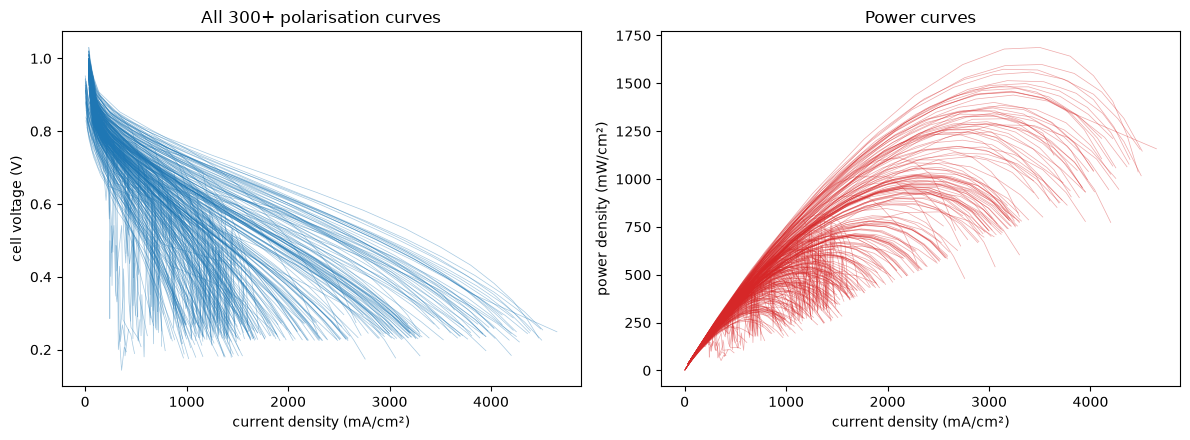

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for cid, g in pol.groupby("curve_id"):
    g = g.sort_values("current_density")
    axes[0].plot(g.current_density, g.cell_voltage, lw=0.5, alpha=0.4, color="tab:blue")
    axes[1].plot(g.current_density, g.current_density * g.cell_voltage, lw=0.5, alpha=0.4, color="tab:red")
axes[0].set(xlabel="current density (mA/cm²)", ylabel="cell voltage (V)", title="All 300+ polarisation curves")
axes[1].set(xlabel="current density (mA/cm²)", ylabel="power density (mW/cm²)", title="Power curves")
savefig("01_all_curves.png")

pressure {5.0: 341.0, 15.0: 416.0, 25.0: 482.0}
relative_humidity {30.0: 402.0, 50.0: 419.0, 80.0: 371.0, 100.0: 439.0}
membrane_compression {5.0: 357.0, 12.0: 488.0}
nafion_percent {20.0: 415.0, 25.0: 411.0}


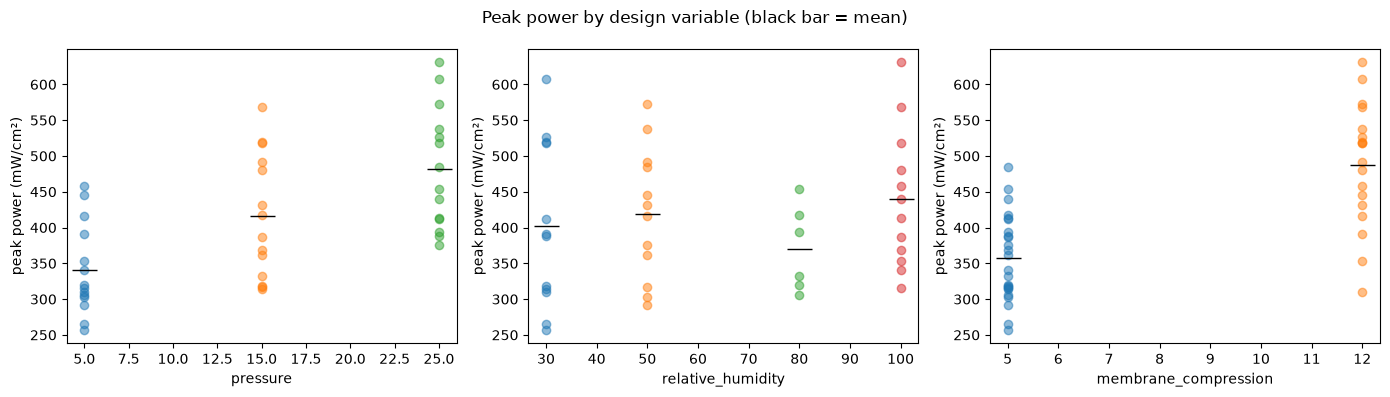

In [9]:
# Effect of operating conditions in the Nafion standard test (the only file with all design variables)
nd = pol.dropna(subset=["nafion_percent"])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, var in zip(axes, ["pressure", "relative_humidity", "membrane_compression"]):
    for lvl, g in nd.groupby(var):
        peak = g.groupby("curve_id").apply(lambda x: (x.current_density * x.cell_voltage).max())
        ax.scatter([lvl] * len(peak), peak, alpha=0.5, label=f"{lvl:g}")
        ax.plot([lvl], [peak.mean()], "k_", ms=18)
    ax.set(xlabel=var, ylabel="peak power (mW/cm²)")
fig.suptitle("Peak power by design variable (black bar = mean)")
savefig("01_peak_power_by_variable.png")

peak = nd.groupby("curve_id").apply(lambda x: pd.Series({"peak_power": (x.current_density * x.cell_voltage).max(),
        **{v: x[v].iloc[0] for v in ["pressure", "relative_humidity", "membrane_compression", "nafion_percent"]}}))
for v in ["pressure", "relative_humidity", "membrane_compression", "nafion_percent"]:
    print(v, peak.groupby(v).peak_power.mean().round(0).to_dict())

**Reading the plots.** The printed means show the direction of each variable on peak power (mW/cm²) in this designed experiment. They are associations of one MEA design, not isolated causal effects, because the levels are crossed unevenly (a few combinations are missing). Notebook 02 quantifies them with the physics descriptors and a model.

## 5. Impedance data (EIS)

In [10]:
eis = eis_summary()
print(eis.shape)
eis.groupby("test_family")[["hfr_proxy", "arc_width"]].median().round(3)

(726, 9)


,hfr_proxy,arc_width
test_family,,
Activation Test MEA Constant Current 0.25A,0.065,0.282
Activation Test MEA Constant Voltage 0.6V,0.043,0.161
Activation Test MEA Constant Voltage 0.6V-2,0.063,0.278
Activation Test MEA Constant Voltage 0.6V-3,0.063,0.235
Activation Test MEA Constant Voltage 0.6V-4,0.058,0.149
Activation Test MEA Cycling Potential,0.048,0.388
Activation Test MEA Standard Protocol,0.061,0.187
Activation Test MEA Standard Protocol (Repeat),0.061,0.150


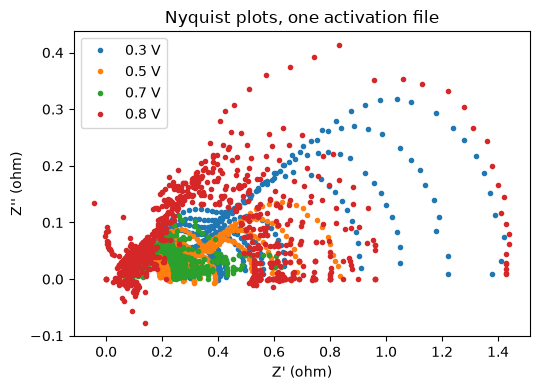

In [11]:
e = load_eis()
sub = e[(e.source_file == e.source_file.iloc[0])]
fig, ax = plt.subplots(figsize=(5.5, 4))
for v, g in sub.groupby("applied_voltage"):
    ax.plot(g.z_real, g.z_img, ".", label=f"{v} V")
ax.set(xlabel="Z' (ohm)", ylabel="Z'' (ohm)", title="Nyquist plots, one activation file")
ax.legend()
savefig("01_nyquist_example.png")

The impedance files have **no frequency column**, so only two proxies are used: the smallest real part (`hfr_proxy`, ohmic resistance) and the real-axis span of the sampled arc (`arc_width`). They give context for the diagnosis in notebook 02, never a fitted equivalent circuit.

---
## 6. DFT track — the descriptor table and its provenance

Each row is one candidate surface (composition, facet, structure) with adsorption energies of OH, O and OOH relative to H2O and H2. The four ORR steps and the **limiting potential** follow by formula (computational hydrogen electrode, `src/dft.py`). `provenance` separates calculated values, machine-learned-potential values, literature copies, toys, synthetic rows and ML predictions; **only `dft`, `mlip` and `literature_user` may support a recommendation**.

In [12]:
from src import dft as D
from src.functions import get_context, get_dft
ctx = get_context(llm=llm)
info = get_dft(ctx)
dft = info["table"]
DEMO = not info["trusted"]
print("DFT table source:", info["source"], "| rows:", len(dft), "| chemical systems:", dft.chemical_system.nunique())
if DEMO:
    print("\n" + "!" * 78 + "\n  SYNTHETIC DEMO DATA: every DFT-like number below is NOT a calculation result.\n"
          "  Put real values in data/dft/dft_table.csv (see data/dft/README.md) to get real results.\n" + "!" * 78)
print(dft.groupby("provenance").size().rename("rows"))
dft[["system_id", "composition", "facet", "structure", "E_OH", "E_O", "E_OOH", "dG_OH", "U_L", "eta", "provenance"]].head(8).round(3)

DFT table source: SYNTHETIC DEMO TABLE (not DFT) | rows: 111 | chemical systems: 10

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
  SYNTHETIC DEMO DATA: every DFT-like number below is NOT a calculation result.
  Put real values in data/dft/dft_table.csv (see data/dft/README.md) to get real results.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
provenance
synthetic_demo    111
Name: rows, dtype: int64


,system_id,composition,facet,structure,E_OH,E_O,E_OOH,dG_OH,U_L,eta,provenance
0,DEMO-000,Pt3Ni,111,bulk,0.455,1.407,3.665,0.805,0.651,0.579,synthetic_demo
1,DEMO-001,Pt3Ni,111,skin,0.266,1.002,3.426,0.616,0.436,0.794,synthetic_demo
2,DEMO-002,Pt3Ni,100,bulk,0.319,1.153,3.540,0.669,0.534,0.696,synthetic_demo
3,DEMO-003,Pt3Ni,100,skin,0.247,1.207,3.434,0.597,0.597,0.633,synthetic_demo
4,DEMO-004,Pt3Ni,110,bulk,0.259,1.021,3.479,0.609,0.463,0.767,synthetic_demo
5,DEMO-005,Pt3Ni,110,skin,0.154,0.841,3.402,0.504,0.386,0.844,synthetic_demo
6,DEMO-006,PtNi,111,bulk,0.259,1.083,3.452,0.609,0.524,0.706,synthetic_demo
7,DEMO-007,PtNi,111,skin,0.148,0.939,3.469,0.498,0.491,0.739,synthetic_demo


{'n': 111, 'slope': 1.025, 'intercept': 3.187, 'rmse': 0.078, 'r2': 0.867}


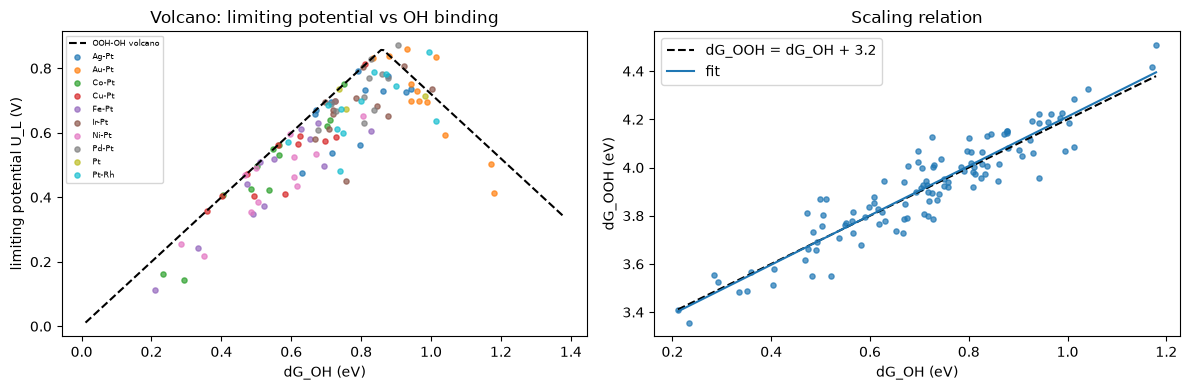

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.linspace(dft.dG_OH.min() - .2, dft.dG_OH.max() + .2, 200)
ax[0].plot(x, D.volcano_curve(x), "k--", label="OOH-OH volcano")
for name, g in dft.groupby("chemical_system"): ax[0].scatter(g.dG_OH, g.U_L, s=14, alpha=.7, label=name)
ax[0].set(xlabel="dG_OH (eV)", ylabel="limiting potential U_L (V)", title="Volcano: limiting potential vs OH binding"); ax[0].legend(fontsize=6)
sc = D.fit_scaling(dft)
ax[1].scatter(dft.dG_OH, dft.dG_OOH, s=14, alpha=.7); xx = np.linspace(dft.dG_OH.min(), dft.dG_OH.max(), 20)
ax[1].plot(xx, xx + D.OOH_OH_OFFSET, "k--", label="dG_OOH = dG_OH + 3.2"); ax[1].plot(xx, sc["slope"] * xx + sc["intercept"], label="fit")
ax[1].set(xlabel="dG_OH (eV)", ylabel="dG_OOH (eV)", title="Scaling relation"); ax[1].legend()
savefig("01_dft_volcano_scaling.png")
print({k: round(v, 3) for k, v in sc.items()})

**What to check in a DFT table before modelling.** (1) The scaling slope should be close to 1 and the offset near 3.2 eV, with scatter of a few tenths of an eV; a table that departs strongly from that has a reference or unit problem. (2) Energies from different functionals or codes must not be mixed without a Pt(111) reference computed the same way. (3) `reference` must say where each value came from. On the demo table the scaling fit reproduces the offset because the toy model was built to do so, which proves nothing about real surfaces.

---
## 7. Model track — the target and the split

* **Target:** `cell_voltage` (V), a regression. Predictors: current density, pressure, relative humidity, compression, Nafion %, activation set, test family. `power_density` is excluded.
* **Split once:** 22% of the **source files** held out (`random_state` = `RANDOM_STATE`), because rows of one curve are near copies of each other. A random row split would make testing look easier than it is. The test files are **not touched again until notebook 03**. Model selection in notebook 02 uses grouped CV inside the training files.
* This is not external-laboratory validation: related protocols can appear on both sides.

In [14]:
from src.models import holdout_split, GROUP
train, test = holdout_split(pol)
print(f"train: {len(train):,} rows, {train[GROUP].nunique()} files | test: {len(test):,} rows, {test[GROUP].nunique()} files")
print("test files:"); print(*sorted(test[GROUP].unique()), sep="\n")
assert set(train[GROUP]).isdisjoint(test[GROUP])

train: 3,679 rows, 20 files | test: 1,285 rows, 6 files
test files:
Activation Test MEA Constant Current 0.25A/4.csv
Activation Test MEA Constant Voltage 0.6V-3/6.csv
Activation Test MEA Constant Voltage 0.6V-4/4.csv
Activation Test MEA Constant Voltage 0.6V-4/6.csv
Activation Test MEA Cycling Potential/5.csv
Standard Test of Nafion Membrane 112/1.csv


**The same discipline for the comment classifiers (notebook 02):** the synthetic comment corpus is split **by observation phrase**, so that no wording appears in both train and test.

---
## 8. LLM track — the documents and the evaluation set

* **Documents:** 30 short original notes (`data/knowledge/K01..K30.md`), each one idea of 70 to 110 words with metadata (`topic`, `evidence`, `tags`). Each note is one chunk; a 40-word chunking is tested in notebook 02.
* **Evaluation set:** 26 questions with the acceptable source note(s) for each, including **4 that the knowledge base cannot answer** (a car lifetime, a value ECSIM never reported, a sports result, a metal price). Fixed in `eval/eval_questions.json` and exported to `data/eval_questions.csv`.

> **Honest caveat.** The notes and the questions were written by the same author in the same session. The set is fixed and versioned *before the pipeline is evaluated*, but retrieval scores will be **optimistic**. Add questions from someone who has not read the notes.

In [15]:
from src.evaluation import load_questions
questions = load_questions()
eq = pd.DataFrame(questions)
eq["gold_docs"] = eq.gold_docs.apply(lambda g: ",".join(g))
eq.to_csv(ROOT / "data" / "eval_questions.csv", index=False)
print(len(eq), "questions;", int((~eq.answerable).sum()), "out of scope")
print(pd.DataFrame(docs).groupby(["topic", "evidence"]).size().unstack(fill_value=0))
eq[["id", "question", "answerable", "gold_docs", "category"]]

38 questions; 6 out of scope
evidence         dataset  literature  textbook
topic                                         
catalyst               0           3         1
catalyst-layer         0           3         0
dataset                2           0         0
dft-descriptors        0           4         0
dft-method             0           3         3
dft-ml                 0           1         2
dft-stability          0           2         1
diagnosis              0           0         5
durability             0           2         3
kinetics               0           0         1
metrics                0           1         1
ohmic                  0           1         0
operating              0           0         3
protocol               0           1         1
scope                  0           0         1
water                  0           0         1


,id,question,answerable,gold_docs,category
0,Q01,Why does the cathode cause most of the activat...,True,K01,kinetics
1,Q02,What does a Tafel slope tell me about oxygen r...,True,K01,kinetics
2,Q03,What are the risks of switching from Pt/C to a...,True,K03,catalyst
3,Q04,Why are Fe-N-C cathodes prone to flooding and ...,True,K05,catalyst
4,Q05,What happens to the catalyst layer when carbon...,True,K06,durability
5,Q06,Which processes reduce platinum surface area o...,True,K07,durability
6,Q07,How does too much Nafion in the catalyst layer...,True,K08,catalyst-layer
7,Q08,How can I tell flooding from membrane dehydrat...,True,K09,water
8,Q09,Does raising backpressure always improve catho...,True,K10,operating
9,Q10,What does over-compressing the gas diffusion l...,True,K12,ohmic


---
## 9. The baselines

The simplest thing that could work, scored with the **same evaluation** as the final solution.

### 9a. Voltage: the mean predictor

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
base = np.full(len(test), train.cell_voltage.mean())
mae0 = mean_absolute_error(test.cell_voltage, base)
print(f"Mean-voltage baseline on held-out files: MAE = {mae0:.3f} V, RMSE = {mean_squared_error(test.cell_voltage, base)**0.5:.3f} V")
print("Every later model is read against this number (a model must beat it clearly to be useful).")

Mean-voltage baseline on held-out files: MAE = 0.194 V, RMSE = 0.224 V
Every later model is read against this number (a model must beat it clearly to be useful).


### 9b. Knowledge answers: keyword search (BM25) and, if connected, the LLM alone

* **Retrieval baseline:** plain BM25 keyword search over whole notes, scored with hit@k and MRR on the evaluation set.
* **LLM-alone baseline:** the model answers with **no retrieval and no tools**; this needs a live key, so offline it is skipped and said so.

In [17]:
from openai import OpenAI
import os
if MODE == "LIVE" and client is not None:
    print([m.id for m in client.models.list()])
else:
    print("No live OpenAI client. Run the connection panel and check its API-key settings.")

['gpt-5.4-2026-03-05', 'gpt-5-nano', 'gpt-5.4-mini', 'gpt-5.5-pro', 'gpt-audio-2025-08-28', 'gpt-4o-mini-transcribe-2025-03-20', 'gpt-5.4-mini-2026-03-17', 'text-embedding-3-large', 'tts-1', 'gpt-5-mini', 'gpt-5-mini-2025-08-07', 'gpt-audio-1.5', 'gpt-image-1.5', 'gpt-4o-2024-11-20', 'gpt-5.1', 'whisper-1', 'gpt-5-pro', 'gpt-realtime-whisper', 'o3-pro-2025-06-10', 'chat-latest', 'gpt-realtime-translate', 'gpt-5.4-pro-2026-03-05', 'o3-pro', 'gpt-4o-2024-08-06', 'o3', 'gpt-realtime-2.1-mini', 'gpt-realtime-2025-08-28', 'gpt-4.1-mini', 'gpt-4o-mini', 'gpt-4o-transcribe-diarize', 'gpt-5.1-2025-11-13', 'gpt-4o-mini-tts-2025-12-15', 'gpt-audio', 'gpt-5.3-codex', 'gpt-5-search-api-2025-10-14', 'gpt-5', 'gpt-4o-mini-transcribe', 'gpt-image-2-2026-04-21', 'gpt-transcribe', 'gpt-4o-mini-2024-07-18', 'gpt-4.1-2025-04-14', 'gpt-image-2.6-sunburst', 'gpt-5-nano-2025-08-07', 'gpt-4o-transcribe', 'gpt-image-2.5-sunburst-2026-09-08', 'tts-1-hd', 'gpt-realtime-1.5', 'gpt-realtime', 'gpt-5.2-pro', 'gpt-

In [18]:
from src.rag import build_retriever
from src.evaluation import retrieval_eval
bm25 = build_retriever("bm25")
base_ret = {k: retrieval_eval(bm25, questions, k) for k in (2, 4)}
print("BM25 baseline:", {k: {m: round(v, 3) for m, v in d.items()} for k, d in base_ret.items()})

from src.functions import llm_alone_eval
alone = llm_alone_eval(questions, llm) if MODE == "LIVE" else None
if alone is None:
    print("LLM-alone baseline: not run (no live connection). Set the key in the panel above and rerun this cell.")
else:
    print("LLM alone: refuses", f"{alone[~alone.answerable].refused.mean():.0%}", "of out-of-scope questions; cites a source for",
          f"{alone.cites_note.mean():.0%}", "of answers; mean tokens", int((alone.prompt_tokens + alone.completion_tokens).mean()))
alone

BM25 baseline: {2: {'hit@k': 0.875, 'MRR': 0.87, 'n': 32}, 4: {'hit@k': 0.969, 'MRR': 0.87, 'n': 32}}
LLM-alone baseline: not run (no live connection). Set the key in the panel above and rerun this cell.


### 9c. Comments: majority class and a lexicon rule

Both are scored on unseen observation wording in notebook 02, next to the trained classifiers.

### 9d. DFT screening: simple rankings, scored on the same evaluation

Rank candidates by **one quantity**: strain (lattice mismatch vs Pt), electronegativity difference, the d-band centre (needs a DFT density of states) and, as an **oracle**, the volcano value from the DFT ΔG_OH (needs the DFT adsorption calculation the ML model is trying to avoid). Metrics against the true limiting potential: Spearman ρ and recall of the true top 10%.

In [19]:
from src.dft_ml import evaluate_baselines
dft_base = evaluate_baselines(dft)
dft_base.round(3)

,method,needs_DFT_for_candidate,spearman,top10pct_recall
0,strain heuristic (compressive = better),False,-0.663,0.000
1,electronegativity vs Pt (closer = better),False,0.595,0.091
2,d-band centre (lower = better),True,0.256,0.364
3,ORACLE: volcano from the DFT dG_OH (needs DFT),True,0.842,0.182


---
## 10. What the baselines tell you

* **Voltage:** the mean predictor has a held-out MAE near **0.19 V** and R² ≈ 0: the cell voltage varies by almost 1 V along a curve, so *any* useful model must use current density. This is the number to beat; a model that gets 0.08 V is not magic, it is learning the shape of a polarisation curve.
* **Retrieval:** BM25 already finds a gold note in the top 4 for essentially every answerable question. On this small, clean knowledge base the retrieval baseline is **hard to beat**, so the interesting question in notebook 02 is not "does hybrid retrieval win?" but "where does answering still fail?" (refusals, citations, paraphrase).
* **LLM alone:** the live comparison shows whether the model, with no sources, invents answers to the out-of-scope questions and whether it can cite anything. Offline this row is empty by design.
* **DFT screening:** a cheap single-quantity ranking is a weak guide, and even the oracle (the volcano of the DFT ΔG_OH) is not perfect because it ignores the O and OOH steps. The question for notebook 02 is whether an uncertainty-aware ML model on *cheap* features gets close to the oracle without computing the adsorption energies. On the synthetic demo table these numbers only exercise the method.
* **What I expect the solution to fix:** a voltage model that beats 0.19 V by a wide margin on unseen files; failure flags that name the right *zone*; answers that cite a retrieved note or refuse.